# Desafio SYNAPTA - Opção 1: Preços de Aluguéis em São Paulo
* **Candidato:** Erick Rafael Gonçalves da Silva
* **Objetivo:** Analisar características de imóveis (área, quartos, vagas, bairro) e sua relação com o valor do aluguel.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import lineStyles
from IPython.display import display

In [33]:
df_alugueis = pd.read_csv("../data/data.csv", encoding="utf-8", low_memory=False)

display(df_alugueis.head(10))
display(df_alugueis.info())
display(df_alugueis.describe())

,address,district,area,bedrooms,garage,type,rent,total
0,Rua Herval,Belenzinho,21,1,0,Studio e kitnet,2400,2939
1,Avenida São Miguel,Vila Marieta,15,1,1,Studio e kitnet,1030,1345
2,Rua Oscar Freire,Pinheiros,18,1,0,Apartamento,4000,4661
3,Rua Júlio Sayago,Vila Ré,56,2,2,Casa em condomínio,1750,1954
4,Rua Barata Ribeiro,Bela Vista,19,1,0,Studio e kitnet,4000,4654
5,Rua Domingos Paiva,Brás,50,2,1,Apartamento,3800,4587
6,Rua Guararapes,Brooklin Paulista,72,2,1,Apartamento,3500,5187
7,Avenida Cásper Líbero,Centro,26,1,0,Studio e kitnet,1727,2244
8,Rua José Peres Campelo,Piqueri,32,2,0,Apartamento,1200,1592
9,Rua Guaperuvu,Vila Aricanduva,36,1,0,Apartamento,1200,1501


<class 'pandas.DataFrame'>
RangeIndex: 11657 entries, 0 to 11656
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   address   11657 non-null  str  
 1   district  11657 non-null  str  
 2   area      11657 non-null  int64
 3   bedrooms  11657 non-null  int64
 4   garage    11657 non-null  int64
 5   type      11657 non-null  str  
 6   rent      11657 non-null  int64
 7   total     11657 non-null  int64
dtypes: int64(5), str(3)
memory usage: 728.7 KB


None

,area,bedrooms,garage,rent,total
count,11657.000000,11657.000000,11657.000000,11657.000000,11657.000000
mean,84.655658,1.966286,1.060393,3250.814789,4080.030625
std,74.020536,0.931313,1.132349,2650.711557,3352.480274
min,0.000000,0.000000,0.000000,500.000000,509.000000
25%,40.000000,1.000000,0.000000,1590.000000,1996.000000
50%,60.000000,2.000000,1.000000,2415.000000,3057.000000
75%,96.000000,3.000000,2.000000,3800.000000,4774.000000
max,580.000000,6.000000,6.000000,25000.000000,28700.000000


### Descrição das Colunas Utilizadas:
* **address:** Endereço completo ou rua do imóvel anunciado.
* **district:** Bairro onde o imóvel está localizado.
* **area:** Área útil do imóvel em metros quadrados ($m^2$).
* **bedrooms:** Quantidade de quartos disponíveis no imóvel.
* **garage:** Quantidade de vagas de garagem.
* **type:** Tipo do imóvel (ex: Apartamento, Casa em condomínio, Studio e kitnet).
* **rent:** Valor mensal do aluguel anunciado (em Reais).
* **total:** Valor total mensal considerando taxas adicionais.

In [34]:
# Verificação de valores ausentes (nulos) por coluna
print("Valores ausentes por coluna:")
print(df_alugueis.isnull().sum())

print("\n" + "="*40 + "\n")

# Verificação de registros duplicados
duplicados = df_alugueis.duplicated().sum()
print(f"Quantidade de linhas duplicadas: {duplicados}")

Valores ausentes por coluna:
address     0
district    0
area        0
bedrooms    0
garage      0
type        0
rent        0
total       0
dtype: int64


Quantidade de linhas duplicadas: 0


### Preparação e Limpeza dos Dados
Durante a inspeção inicial através do `.describe()`, identificou-se que as colunas `area` e `rent` apresentavam valores mínimos iguais a `0.0`. Como um imóvel físico não pode possuir área ou aluguel zerados, esses registros inconsistentes foram filtrados para evitar distorções nas análises estatísticas.

In [35]:
# Filtrando apenas imóveis com área e aluguel maiores que zero
df_limpo = df_alugueis[(df_alugueis['area'] > 0) & (df_alugueis['rent'] > 0)].copy()

# Exibindo o resumo da limpeza
print(f"Total de linhas antes da limpeza: {len(df_alugueis)}")
print(f"Total de linhas após a limpeza: {len(df_limpo)}")
print(f"Registros removidos: {len(df_alugueis) - len(df_limpo)}")

Total de linhas antes da limpeza: 11657
Total de linhas após a limpeza: 11655
Registros removidos: 2


In [36]:
media_rent = df_limpo['rent'].mean()
mediana_rent = df_limpo['rent'].median()

print(f"Preço Médio do Aluguel: R$ {media_rent:.2f}")
print(f"Preço Mediano do Aluguel: R$ {mediana_rent:.2f}")

Preço Médio do Aluguel: R$ 3250.96
Preço Mediano do Aluguel: R$ 2415.00


### Por que a média e a mediana são diferentes?
* **Média:** É calculada somando todos os valores e dividindo pela quantidade. Ela é altamente sensível a valores extremos (como mansões ou coberturas de altíssimo luxo), o que puxa o valor da média para cima.
* **Mediana:** É o valor que ocupa a posição central quando os dados estão ordenados. Por ser imune a valores extremos, ela representa de forma mais realista o "aluguel típico" pago pela maioria da população.

In [37]:
# Filtrando apenas bairros com pelo menos 30 anúncios para garantir relevância estatística
contagem_bairros = df_limpo['district'].value_counts()
bairros_validos = contagem_bairros[contagem_bairros >= 30].index
df_bairros_filtrados = df_limpo[df_limpo['district'].isin(bairros_validos)]

# Calculando a média por bairro
media_por_bairro = df_bairros_filtrados.groupby('district')['rent'].mean()

print("--- TOP 5 BAIRROS COM MAIORES PREÇOS MÉDIOS ---")
print(media_por_bairro.sort_values(ascending=False).head(5))

print("\n--- TOP 5 BAIRROS COM MENORES PREÇOS MÉDIOS ---")
print(media_por_bairro.sort_values(ascending=True).head(5))

--- TOP 5 BAIRROS COM MAIORES PREÇOS MÉDIOS ---
district
Jardim Leonor      7455.736842
Tamboré            6912.676471
Cerqueira César    6750.657143
Jardim Paulista    6305.963636
Paraíso            6285.561798
Name: rent, dtype: float64

--- TOP 5 BAIRROS COM MENORES PREÇOS MÉDIOS ---
district
Taboão            1473.142857
Sé                1593.301587
Campos Elíseos    1646.786325
Santa Efigênia    1647.534884
Vila Ema          1736.861111
Name: rent, dtype: float64


### Visualização de Dados
Abaixo estão os gráficos criados para explorar a distribuição dos preços, a relação entre a área e o valor do aluguel, e o ranking dos bairros mais caros.

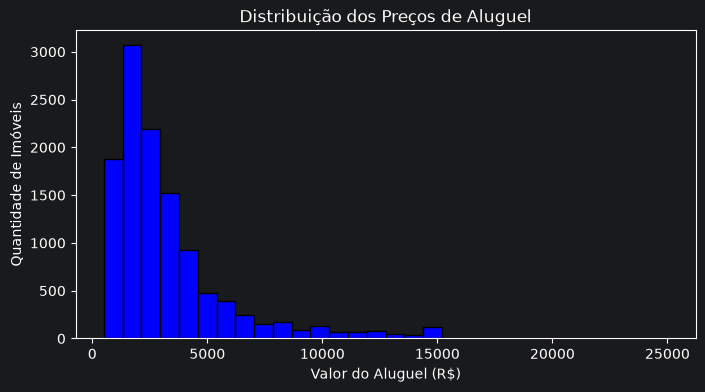

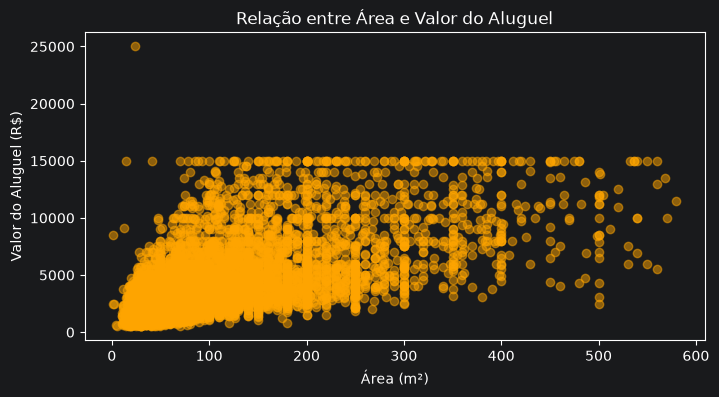

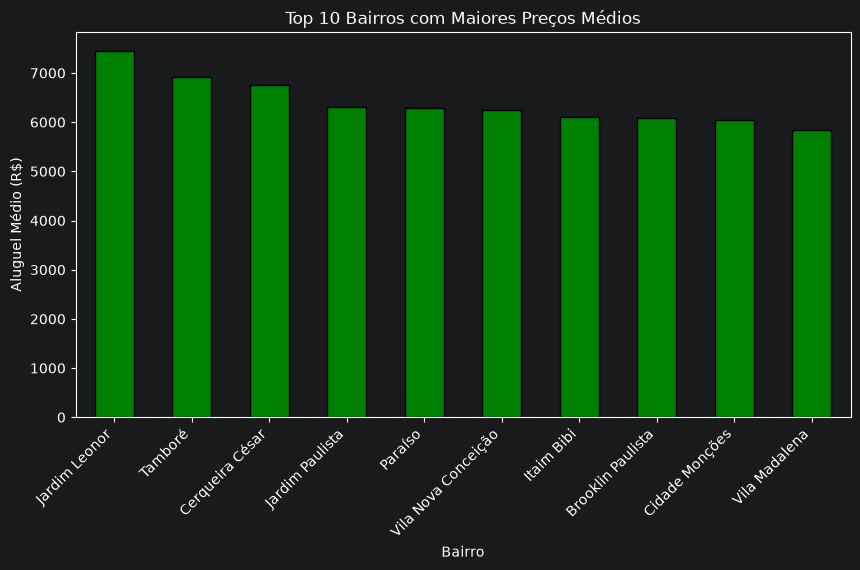

In [38]:
#-------------------------------------------------------------
# GRÁFICO 1: Histograma simples da distribuição dos aluguéis
# -------------------------------------------------------------
plt.figure(figsize=(8, 4))
plt.hist(df_limpo['rent'], bins=30, color='blue', edgecolor='black')
plt.title('Distribuição dos Preços de Aluguel')
plt.xlabel('Valor do Aluguel (R$)')
plt.ylabel('Quantidade de Imóveis')
plt.show()

# -------------------------------------------------------------
# GRÁFICO 2: Gráfico de Dispersão (Área x Aluguel)
# -------------------------------------------------------------
plt.figure(figsize=(8, 4))
plt.scatter(df_limpo['area'], df_limpo['rent'], color='orange', alpha=0.5)
plt.title('Relação entre Área e Valor do Aluguel')
plt.xlabel('Área (m²)')
plt.ylabel('Valor do Aluguel (R$)')
plt.show()

# -------------------------------------------------------------
# GRÁFICO 3: Gráfico de Barras dos Top 10 Bairros Mais Caros
# -------------------------------------------------------------
top10_bairros = media_por_bairro.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top10_bairros.plot(kind='bar', color='green', edgecolor='black')
plt.title('Top 10 Bairros com Maiores Preços Médios')
plt.xlabel('Bairro')
plt.ylabel('Aluguel Médio (R$)')
plt.xticks(rotation=45, ha='right')
plt.show()